# Quickstart: basic tutorial

This notebook shows a minimal example of how to run FLIP on JWST/NIRCam coronagraphy data. More detailed examples on how to optimize PSF subtraction and sensitivity will be added soon. 

## Loading data

First, we need the JWST observations that we will be processing. We need both a science target (where we will look for planets) and a reference target (used for model calibration and to improve the model initial state). Typically you can use as a reference target any observation that you would include in a PSF library for PSF subtraction.

We have some utility functions to turn standard state 2 (calints.fits) JWST data products into FLIP-friendly format. This means that the data must already be processed with the first stages of the [standard JWST pipeline](https://jwst-pipeline.readthedocs.io/en/stable/index.html), including ramp fitting, conversion to physical units and bad pixel flagging. These steps can be easily run with [spaceKLIP](https://spaceklip.readthedocs.io/en/latest/).

The utility functions turn these FITS files (including both the actual science data and the ERR array for noise estimation) into numpy arrays, which we then turn into pyTorch tensors. For simplicity, I have placed some observations from the JWST Early Release Science (ERS) program in this [Google Drive folder](https://drive.google.com/drive/folders/1NH_ucrQnQbod5SDxy5MsJ9aSvSGkqU3V?usp=drive_link). This includes the science target (HIP 65425, both observatory rolls; for this tutorial you can pick any single roll) and the reference target (HIP 68246, all nine dithers; for this tutorial you can pick any single dither). These have already been processed with spaceKLIP through the JWST pipeline, plus some extra bad pixel cleaning steps (though as we will see, this bad pixel cleaning may not be necessary).

Let's load and visualize the data first:

Text(0.5, 1.0, 'HIP 68245 (reference)')

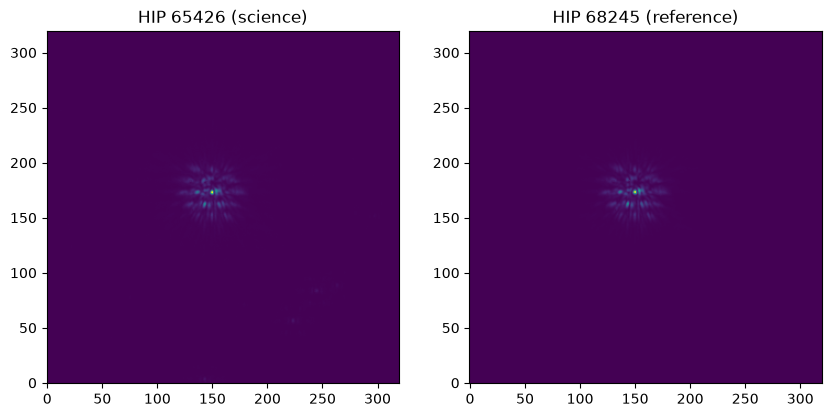

In [ ]:
import matplotlib.pyplot as plt
import astropy.io.fits as fits


science_fits = 'path/to/file/jw01386002001_0310a_00001_nrcalong_calints.fits'
reference_fits = 'path/to/file/jw01386001001_0310e_00001_nrcalong_calints.fits'

plt.figure(figsize=[10,5])
plt.subplot(121)
plt.imshow(fits.getdata(science_fits)[0], origin='lower')
plt.title('HIP 65426 (science)')

plt.subplot(122)
plt.imshow(fits.getdata(reference_fits)[0], origin='lower')
plt.title('HIP 68245 (reference)') 

In [9]:
fits.open(reference_fits)[0].header['CHANNEL']

'LONG'

Now, we will call our JWST NIRCam utility functions to format the data. 

In [ ]:
import os 
# If the environment variables are not set in bashrc, they need to be set here before we import anything else
os.environ["STPSF_PATH"] = "path/to/file/stpsf-data"
os.environ["PYSYN_CDBS"] = "path/to/file/synphot-data"

from pyflip.instruments import JWSTNIRCamData

num_det_px = 80
masktype = 'MASK335R'
DEVICE = 'cuda' # We will run this on a cuda-enabled GPU; you can change this to CPU but the code is less maintained for that case

Text(0.5, 1.0, 'HIP 68245 (reference noise)')

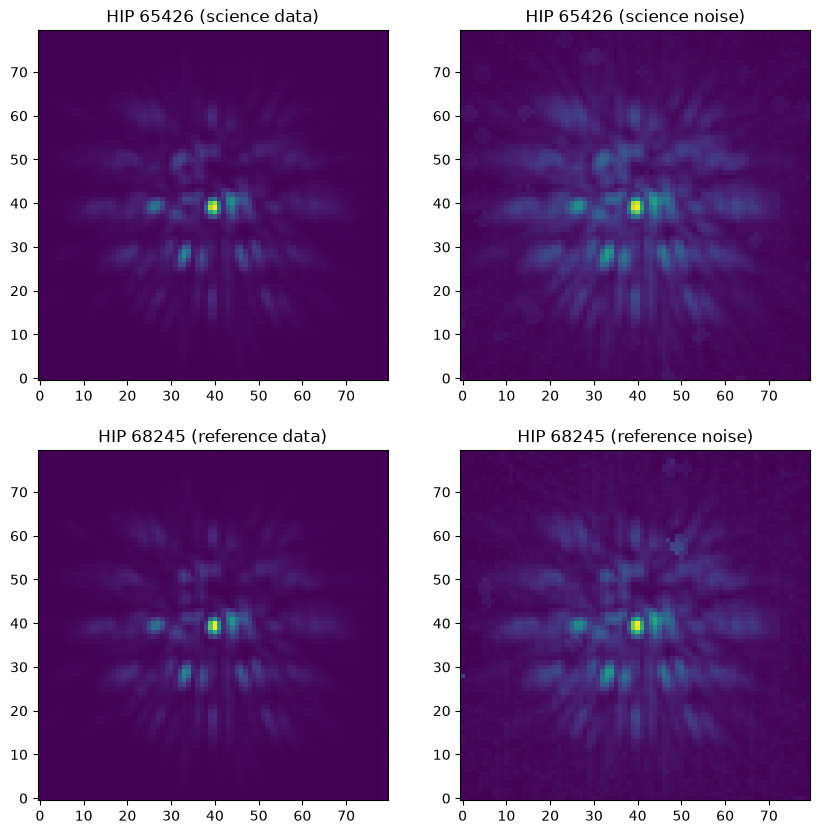

In [ ]:
sci_numpy, scinoise_numpy = JWSTNIRCamData.load_and_crop_obs(science_fits, num_det_px=num_det_px, coron_type=masktype)
ref_numpy, refnoise_numpy = JWSTNIRCamData.load_and_crop_obs(reference_fits, num_det_px=num_det_px, coron_type=masktype)

plt.figure(figsize=[10,10])
plt.subplot(221)
plt.imshow(sci_numpy[0], origin='lower')
plt.title('HIP 65426 (science data)')

plt.subplot(222)
plt.imshow(scinoise_numpy[0], origin='lower')
plt.title('HIP 65426 (science noise)')

plt.subplot(223)
plt.imshow(ref_numpy[0], origin='lower')
plt.title('HIP 68245 (reference data)')

plt.subplot(224)
plt.imshow(refnoise_numpy[0], origin='lower')
plt.title('HIP 68245 (reference noise)')

The function does a few things: crops the images so that the coronagraph center is as close as possible to the center of the image, mean-combines all the integrations, and adds the noise from all the integrations in quadrature. We crop to a 80x80 sub-window because that is where typical PSF subtraction leaves significant starlight residuals. If the mask and filter combination is not one of the pre-defined options, you must manually provide how to crop the image.

Since we are doing model-based PSF subtraction, we need to mask out the bad pixels from our image to avoid biasing the optimization. If you ran the normal JWST pipeline, your images may already have NaNs in them, in which case that is a good starting point: you just need to crop it in the same way that we cropped the science and noise arrays. Otherwise, you can create your own pixel mask as long as it matches the shape of the cropped data.

For convenience, a simple pixel mask is also included in the Google Drive above, so we can start with that.

In [ ]:
import numpy as np 

px_mask = np.load('path/to/filen/pixel_mask.npy')
px_mask = px_mask.astype(np.float32)
px_mask_numpy = px_mask.copy()

Finally, we convert this to pyTorch tensors, which we will use for our optimization.

In [12]:
import torch 

In [ ]:
sci = torch.from_numpy(sci_numpy).to(DEVICE)
ref = torch.from_numpy(ref_numpy).to(DEVICE)
px_mask = torch.from_numpy(px_mask).to(DEVICE)[None] # Needs to be 3D tensor

Great, now we can set up our differentiable NIRCam object!

## Setting up a differentiable NIRCam object

For the most common data types, we have convenience functions that assemble differentiable JWST/NIRCam objects from the observations, through STPSF. Here we also choose the oversampling of our image plane and the number of monochromatic wavefronts to create a "broadband" wavefront. Oversample = 2 we have found is decent in most cases. For wide filters we choose num_wl=21 and for medium-band filters usually num_wl=9, but this can be experimented with. 

In [ ]:
model_dir = 'data_dir_jan'

# Create STPSF model (with minor tweaks) from observation
stpsfmodel = JWSTNIRCamData.create_STPSF_model(from_obs=science_fits)

# Save parameters as required for us
JWSTNIRCamData.generate_STPSF_model_params(stpsfmodel,spec_type='A1V', catalog_spec='phoenix', # spectral type of host star; can also be an empirical spectrum; only used to generate the wavelength sampling
                            num_wl=21,oversample=2,
                            folder_to_save=model_dir)

# Once the two lines above run once, they don't need to be run again: we can just load the products directly here
# to assemble a differentiable NIRCam object
diffNIRCam = JWSTNIRCamData.assemble_JWST_NIRCam_coron(model_dir,num_det_px)

Since the host star also has properties that we want to fit for (e.g., misalignment relative to the coronagraph), we need a differentiable wavefront object too. Optionally this can be one for the science target and one for the reference target, since they are different stars, but for a first approximation we can use the same one since they are very similar stars:

In [ ]:
from pyflip.wavefronts import BroadbandWavefront
import torch.nn as nn

# To get the wavelenght-dependent weights estimated by STPSF: this encapsulates the spectrum of the star and the instrument throughput
_, _, _, _, wlen_weights, _ = JWSTNIRCamData.load_model_data(data_dir=model_dir)

# Set up the wavefront object: this will be propagated by our optical model
initial_star_position = nn.Parameter(torch.FloatTensor([0., 0.])).to(DEVICE) # Relative to coronagraph center
wavefronts = BroadbandWavefront(wlen_weights, angles=initial_star_position).to(DEVICE)

Good! Now we can move on to setting up our actual optimization.

## Optimization setup

We need to set up a few things: the parameters we want to fit in our model and their associated learning rates, the optimizer to use, the learning rate scheduler to use (e.g., slow down the optimization towards the end), the science scale down factor (how much to scale down the gradient when optimizing on the science target relative to the reference target, to make it "less aggressive" and thus less prone to overfitting), and the iteration numbers that define the FLIP stages.

Below are some default choices that work decently for this dataset; see our paper for details (and upcoming tutorials on fine-tuning).

First: we are fitting the star position, the OPD (phase error) at the entrance of the telescope, the internal OPD after the coronagraph mask, and detector flat fields. These can be called from the differentiable NIRCam object we created above.

In [ ]:
# Star parameters

star_position = [wavefronts.angles_offset]

# Instrument parameters
opds = [
    diffNIRCam.optical_system.JWSTPrimary.wfe_offsets.grid,
    diffNIRCam.optical_system.NIRCamLyotstop.wfe_offsets.grid
]

detector_flats = [
    diffNIRCam.optical_system.NIRCamdetector.detector_flat_field.grid
]

Now we set up the optimizer:

In [ ]:
scheduler_iters = 15000
stage_cutoffs = [600, 3500, 5500, 5500+600, 11000]
sci_loss_weight = 0.00005

optimizer_argument = [
        {'params': opds, 'lr': 4e-9},
        {'params': star_position, 'lr': 4e-8},
        {'params': detector_flats, 'lr':4e-5}
    ]

optimizer = torch.optim.AdamW(optimizer_argument, weight_decay=0.0)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=scheduler_iters, eta_min=4e-9) 

To actually apply the optimization stages, we have a convenience function to apply the different optimization stages given stage numbers. These are very simple and customizable; we will use the default one we used for the paper.

In [ ]:
from pyflip.optimization_handlers import default_stages

## Run FLIP

Now we can actually run FLIP! We set up a standard optimization loop. Each round will do the following things:
- Re-start the optimizer
- Forward model a PSF with the current model parameters.
- Compute the difference (the L1 loss) between the data and the model PSF. For stage 1 iterations the data is the reference target; for stage 2 it is our science target.
- Mask out bad pixels using our pixel mask. This prevents them from contributing to the loss function.
- Propagate loss function and populate parameter gradients.
- During stages 1.1 and 2.1, match the model PSF flux to the target flux (currently this is done manually for simplicity; in future releases of the code this will be a differentiable parameter as well)
- Apply the optimization stages (e.g., zero-out the gradients of parameters we don't want to update at a given stage).
- Update parameters
- At some iterations, track and measure diagnostics (e.g., model parameter evolution, loss function vs iteration number, SNR of real or injected planets, etc).

In [ ]:
import tqdm
import torch.nn.functional as F
from pyflip.dl_utils import manual_match_flux, track_SNR # Manual flux match, tracking SNR utils

In [ ]:
tbar = tqdm.tqdm(range(stage_cutoffs[-1] + 1), mininterval=30.0) # Progress bar to end of final stage

save_loss_every = 400 # Measure loss every 400 iterations
measure_SNR_every = 400 # Measure SNR every 400 iterations

losses = []
loss_iters = []

snrs_arr = []
track_SNR_iters = []

outout_dir = 'output'

for i in tbar:

    optimizer.zero_grad(set_to_none=True)

    # Model new PSF
    PSF_model = diffNIRCam(wavefronts)

    if i < stage_cutoffs[2]: # Before this iteration we are in stage 1: calibration on reference star
        loss = F.smooth_l1_loss(PSF_model, ref, reduction='none') # Reduction = none to keep the array shape and mask loss pixels
    else:  # Then we are in stage 2: tuning on science star
        loss = F.l1_loss(PSF_model, sci, reduction='none') * sci_loss_weight # Scale down gradient to make optimization less "aggressive" on science target

    loss *= px_mask 
    loss = loss.sum() / px_mask.sum() 

    loss.backward() # Populate gradients

    if i%save_loss_every==0:
        losses.append(loss.item())
        loss_iters.append(i)

    # Match flux
    if i < stage_cutoffs[0]: 
        wavefronts = manual_match_flux(PSF_model, ref, px_mask, wavefronts)
    elif i > stage_cutoffs[2] and i < stage_cutoffs[3]:
        wavefronts = manual_match_flux(PSF_model, sci, px_mask, wavefronts)

    # Apply stages: prevent update of some parameters
    default_stages(diffNIRCam, wavefronts, i, stage_cutoffs = stage_cutoffs)

    # Update parameters 
    optimizer.step()
    scheduler.step()

    # Below is optional: track some metrics
    # Detaching from the optimization can significantly increase the runtime of the loop;
    # so only run the components below as much as necessary for inspection etc.

    # Optional: End of calibration! Save final reference PSF and residual
    if i == stage_cutoffs[1] -1:
        with torch.no_grad(): # Prevent gradient computation since this is just a metric
            residual_ref = ref - PSF_model
            residual_ref = residual_ref.detach().cpu().numpy()
            model_psf_ref = PSF_model.detach().cpu().numpy()

            np.save(outout_dir+'/residual_ref_jan.npy', residual_ref)
            np.save(outout_dir+'/model_psf_ref_jan.npy', model_psf_ref)
    
    # Optional: Track SNR of real planet (known location in detector coordinates) or injected planets.
    if i%measure_SNR_every == 0 and i > stage_cutoffs[2]: # only measure in science target
        residual_sci = sci - PSF_model
        residual_sci = residual_sci.detach().cpu().numpy()
        # To track SNR we need: location of source (in pixels, in detector coordinates), 
        # aperture size (radius of circle in pixels enclosing the planet PSF), 
        # and annulus width (in pixels, over which to compute noise samples for SNR calculation)
        # If the planet peak flux is known, we can also compute signal loss.

        # Optionally: smooth the image with a Gaussian kernel to remove pixel-to-pixel noise in SNR calculation

        # This assumes that the coronagraph center is quite close to the detector center, and that
        # the star is quite close to the center of the coronagraph. TODO: re-center to star first and then
        # compute these metrics relative to star.

        # HIP 65426 b takes up a lot of the image; so to track the SNR properly we set a 
        # big aperture size (22 pixels) and a big annulus width (6.5 pixels).
        # For more "normal" sources, app_size and ann_width of 3-5 pixels should work,
        # depending on whether we just see the PSF core (lambda/D) or more of it.
        signal_peaks, signal_losses, snrs = track_SNR(residual_sci, i, [{'pos_x_px':-8., 'pos_y_px': 11.}],app_size=22., ann_width=8.,
                                                      track_fluxes=None,mask_name='MASK335R', snr_smooth_sigma=1., px_mask_numpy=px_mask_numpy,
                                                      vis_dir_iterations=outout_dir+'/vis_iters')
        snrs_arr.append(snrs)
        track_SNR_iters.append(i)

    # Optional: End! Save final residual, loss vs iterations, and maybe even final model parameters
    if i == stage_cutoffs[-1]:
        residual_sci = sci - PSF_model
        residual_sci = residual_sci.detach().cpu().numpy()
        np.save(outout_dir+'/residual_sci.npy', residual_sci)

        np.save(outout_dir+'/loss.npy', np.array(losses))
        np.save(outout_dir+'/loss_iters.npy', np.array(loss_iters))
        
        # Example of how to save model parameters at any point
        np.save(outout_dir+'/postmask_OPD.npy', diffNIRCam.optical_system.NIRCamLyotstop.wfe_offsets.grid.detach().cpu().numpy())

        # Save SNR diagnostics 
        snrs_arr = np.array(snrs_arr)
        track_SNR_iters = np.array(track_SNR_iters)

        np.save(outout_dir+'/snrs_arr.npy', snrs_arr)
        np.save(outout_dir+'/track_snr_iters.npy', track_SNR_iters)


And that's a-FLIP.

## Visualize results

We can look at our results now; for example, the evolution in the loss function and the final residual science images.

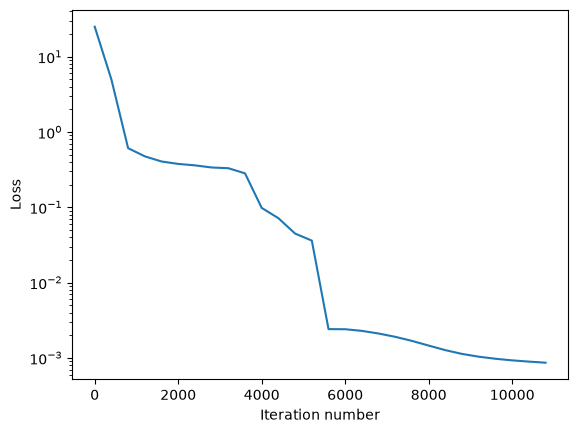

In [ ]:
loss_vals = np.load(outout_dir+'/loss.npy')
loss_iters = np.load(outout_dir+'/loss_iters.npy')

plt.plot(loss_iters, loss_vals)
plt.xlabel('Iteration number')
plt.ylabel('Loss')
plt.yscale('log')

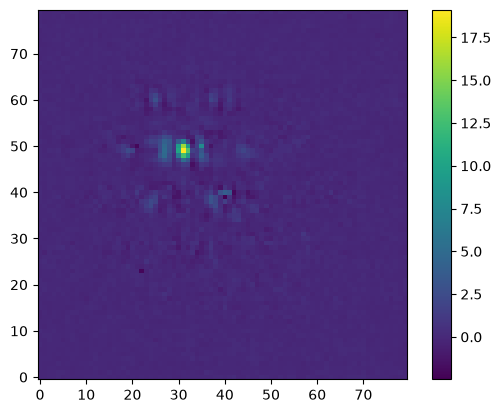

In [ ]:
res_science = np.load('path/to/file/residual_sci0.npy')

plt.imshow(res_science[0], origin='lower')
plt.colorbar()

And there's HIP 65426 b!